# Periodicity Estimation for Star-Planet Interactions

In this notebook we will explore several methods for periodicity extraction -- including the much beloved Lomb-Scargle algorithm, but also the lesser known $Z_n^2$ test and Kuiper's test. 

You will be provided with some basic code, however there will be lines for you to complete yourself following what was covered in the talk. Fear not if you don't remember all of the details from the presentation, there will also be guidance within the markdowns throughout this notebook. 

Happy period hunting! :) 

In [34]:
# imports
import numpy as np
import matplotlib.pyplot as plt
from astropy.timeseries import LombScargle
from astropy.stats import kuiper
import scipy.signal as signal


from maser import maser

## Setting up system geometry

We will be using __[Kavanagh's & Vedantham's (2023)](https://github.com/robkavanagh/maser)__ MASER code to simulate visibility curves for radio emission produced by magnetic star-planet interactions. This tool predicts, given a system geometry, the windows during which we will be able to detect these emissions. 

Here I have entered in parameter values which will give us a misaligned system.


In [2]:
rad_per_deg = np.pi / 180

########################################
# Define system parameters
########################################

# Physical constants
sec_per_day = 86400
Msun = 1.989e33
Rsun = 6.955e10
G = 6.674e-8


# Stellar parameters
M_s = 0.2 					# Stellar mass (solar masses)
R_s = 0.3 					# Stellar radius (solar radii)
P_s = 0.8 					# Rotation period (days)
i_s = 73.0 * rad_per_deg    # Stellar inclination (radians)
B_s = 1e3 					# Polar magnetic field strength (Gauss) 
beta = 45.0 * rad_per_deg	# Magnetic obliquity (radians)
phi_s0 = 0.0				# Stellar rotation phase at time zero (0-1)


# Planet parameters
a = 10						# Planet orbital distance (stellar radii)
i_p = 90.0 * rad_per_deg    # Planet orbital inclination (radians)
lam = 0.0 * rad_per_deg		# Projected spin-orbit angle (radians)
phi_p0 = 0.0 				# Planet orbital phase at time zero (0-1)
P_p = 2*np.pi * ((a * R_s * Rsun) ** 3 / (G * M_s * Msun)) ** 0.5 / sec_per_day  # Planet orbital period (days)
P_syn = 1 / abs(1/P_p - 1/P_s) # Synodic period (days)


# Emission parameters
f = 100						# Observing frequency (MHz)
alpha = 75 * rad_per_deg 	# Emission cone opening angle (radians)
dalpha = 1 * rad_per_deg	# Emission cone thickness (radians)




Next, we define the duration of our simulation (effectively our observing baseline). We want to make sure we have good phase coverage, so I will set the duration of the simulation to be ten times the largest fundamental period in the system (orbital, rotational, or synodic). First, we can print out these periods to see what they are.

In [3]:
periods = [P_p, P_s, P_syn]
print(f"Planet orbital period: {P_p:.2f} days")
print(f"Stellar rotation period: {P_s:.2f} days")
print(f"Synodic period: {P_syn:.2f} days")

# Observing times (days)
times = np.linspace(0, 10*np.max(periods), 100000)

Planet orbital period: 1.35 days
Stellar rotation period: 0.80 days
Synodic period: 1.97 days


### Computing and visualising the light curve

Your first task is to plot the visibility curve. We want to consider the periodicities of emissions stemming from both the northern and southern hemispheres. We are also interested in how emissions from each hemisphere may interact to cancel (or not), and how seeing emission from both impacts the periodicities extracted.

In [28]:
# Calling MASER

params = M_s, R_s, P_s, i_s, B_s, beta, phi_s0, a, i_p, lam, phi_p0, f, alpha, dalpha
N, S = maser(params, times)
N = N.astype(int)
S = S.astype(int)


In [14]:
# combine the emissions from N and S (destructively) 

C = '%%% EDIT THIS'

In [11]:
# plot the resulting visbility curves for N, S, and C (combined)



### Extracting periodicities

We will now use Lomb-Scargle, the $Z_n^2$ test, and Kuiper's test to determine the periodicity of the emissions from this system. 

#### Provided functions

In the below cell, I provide you with two complete functions: one which computes the period grid that will be input into each algorithm and one which determines the "event" times of the emissions (since the $Z_n^2$ test and Kuiper's test take only event times and not the full time series).

In [12]:
###### COMMENT THIS FUNCTION -- EXPLAIN THAT IT IS UNIFORMLY SPACED IN PERIOD-SPACE NOT FREQUENCY

def period_grid(times, star_period, planet_period, synodic_period, oversampling_factor=10):
    baseline = times.max() - times.min()
    if baseline <= 0: return None

    median_resolution = np.median(np.diff(times))
    if median_resolution <= 0: return None

    max_period = baseline/2

    min_period_phys = np.min([star_period, planet_period, synodic_period])/6
    min_period_sampling = 2*median_resolution
    min_period = np.max([min_period_phys, min_period_sampling])

    dp = min_period**2/(oversampling_factor*baseline)
    N_steps = int((max_period - min_period) / dp)

    period_grid = np.linspace(min_period, max_period, N_steps)

    if period_grid[0] <= 0 or np.any(np.diff(period_grid) <= 0): return None
        
    return period_grid



###### COMMENT THIS FUNCTION 
def pulse_centres(times, visibility):
    visibility = np.asarray(visibility)

    # Indices where visibility == 1
    pulse_idx = np.where(visibility > 0)[0]

    if len(pulse_idx) == 0:
        return np.array([])

    # Find breaks between consecutive pulse samples
    breaks = np.where(np.diff(pulse_idx) > 1)[0]

    # Split into contiguous pulse segments
    segments = np.split(pulse_idx, breaks + 1)

    centres = []
    for seg in segments:
        start = seg[0]
        end = seg[-1]
        centres.append(0.5 * (times[start] + times[end]))

    return np.array(centres)



    


In [16]:
# period grid
periods = period_grid(times, P_s, P_p, P_syn)

pulse_times_N = pulse_centres(times, N)
pulse_times_S = pulse_centres(times, S)
pulse_times_C = pulse_centres(times, C)

UFuncTypeError: ufunc 'greater' did not contain a loop with signature matching types (<class 'numpy.dtypes.StrDType'>, <class 'numpy.dtypes._PyLongDType'>) -> None

#### Constructing a Lomb-Scargle periodogram


In [ ]:
# runs LS then plot the periodogram for N, S, and C (combined)

# function for runnning LS
def run_ls(times, visibility, periods):

    frequencies = 1/periods

    ls = LombScargle(times, visibility)
    data_power = ls.power(frequencies) 

    return data_power


# plot the periodogram





#### Constructing a $Z_n^2$ test periodogram


Maximum harmonic set by: $n = 1/(1.7\delta)$

In [ ]:
def run_zn2(pulse_times, visibility, periods, max_harmonic):
    Z = np.zeros(len(periods))

    # phase fold the pulse times
    for i, P in enumerate(periods):
        phi = (pulse_times / P) % 1
        theta = 2*np.pi*phi

        # compute the Z^2_n statistic
        z = 0
        for k in range(1, max_harmonic+1):
            C = np.sum(np.cos(k*theta))
            S = np.sum(np.sin(k*theta))
            z += C**2 + S**2
        Z[i] = 2*z/len(phi)
    return Z



# calculate max harmonic and run z test - then plot results








#### Constructing a Kuiper's test periodogram


In [ ]:
# run Kuiper then plot the periodogram for N, S, and C (combined)

def run_kuiper(pulse_times, visibility, periods):
    if len(pulse_times) < 5:
        return None

    D_scores = []

    for T in periods:
        phases = (pulse_times / T) % 1
        D, _ = kuiper(phases)
        D_scores.append(D)

    return np.asarray(D_scores)


# plot periodograms




### Extract the six most dominant peaks from each periodogram

In [ ]:

def locate_peak_periods(power_func, periods, num_peaks, prominence_frac=0.2): 
    
    top_powers = np.full(num_peaks, np.nan)
    top_periods = np.full(num_peaks, np.nan)
    FWHM = np.full(num_peaks, np.nan)

    power_func = np.asarray(power_func, dtype=float)
    periods = np.asarray(periods, dtype=float)

    prom_min = prominence_frac * (np.nanmax(power_func) - np.nanmin(power_func))

    peak_idx, _ = signal.find_peaks(power_func, prominence=prom_min)
    if len(peak_idx) == 0: return top_powers, top_periods, FWHM

    n = min(len(peak_idx), num_peaks)
    candidate_powers = power_func[peak_idx]
    candidate_periods = periods[peak_idx]
    ordered_idx = np.argsort(candidate_powers)[::-1][:n]

    top_powers[:n] = candidate_powers[ordered_idx]
    top_periods[:n] = candidate_periods[ordered_idx]

    dp = periods[1] - periods[0]
    widths = signal.peak_widths(power_func, peak_idx[ordered_idx], rel_height=0.5)[0]*dp 
    FWHM[:n] = widths

    return top_powers, top_periods, FWHM



# extract the top 6 for N, S, and C (combined) for each of the three methods (LS, Z, Kuiper)





### Why do N, S, and C differ?


In [33]:
# consider why the results may differ? 
# you could look at, for example, the duty cycle/pulse counts and/or spin orbit diagram




### Compare top six periods to known periods in the system ###

As we have discussed, the geometry will determine which period dominates. There are two fundamental periods in our system - the planetary orbital period $P_p$ and the stellar rotation period $P_s$ (these also have k harmonics). These period can combine to arrive at the synodic period (i.e., the time taken for both bodies to return to some initial state), $P_{syn} = 1 / abs(1/P_p - 1/P_s)$, but they can also combine in lots of ways $f = nf_1 \pm mf_2$. 

In [ ]:
# use the FWHM (or another tolerance of your choice) to compare known periods in the system to what your periodograms find
# first consider the known periods in the system - fundamentals (and harmonics), synodic (and harmonics), and combined periods
# how many harmonics should you consider? how many combined periods?





def combined_periods(p1, p2, max_harm):
    # checking combinations
    valid = []
    for n in range(-max_harm, max_harm+1):
        for m in range(-max_harm, max_harm+1):
            if n == 0 and m == 0: continue
            freq = n/p1 + m/p2
            if freq == 0: continue 
            valid.append(np.abs(1/freq))
    return valid



def harmonics(p, max_harm):
    harms = []
    for n in range(2, max_harm+1):
        harms.append(p/n)
        harms.append(p*n)

    return harms


star_harmonics = harmonics(P_s, max_harm=6)
planet_harmonics = harmonics(P_p, max_harm=6)
synodic_harmonics = harmonics(synodic_period, max_harm=6)
combined = combined_periods(P_s, P_p, max_harm=3)


star_harmonics.append(P_s)
planet_harmonics.append(P_p)
synodic_harmonics.append(synodic_period)



p = ls_periods_N
tolerances = FWHM_N

for i in range(len(p)):
    if abs(p[i] - P_p) < tolerances[i]/:
        print('Peak', {i+1}, 'is planet')
# else: print('It is not planet')
    for harm in planet_harmonics:
        if abs(p[i] - harm) < tolerances[i]:
            print('Peak', {i+1}, 'is planet harmonic:', harm)
    # else: print('It is not planet harmonic')

for i in range(len(p)):
    if abs(p[i] - P_s) < tolerances[i]:
        print('Peak', {i+1}, 'is star')
# else: print('It is not planet')
    for harm in star_harmonics:
        if abs(p[i] - harm) < tolerances[i]:
            print('Peak', {i+1}, 'is star harmonic:', harm)


for i in range(len(p)):
    if abs(p[i] - synodic_period) < tolerances[i]:
        print('Peak', {i+1}, 'is synodic')
# else: print('It is not planet')
    for harm in synodic_harmonics:
        if abs(p[i] - harm) < tolerances[i]:
            print('Peak', {i+1}, 'is synodic harmonic:', harm)


for i in range(len(p)):
    # if abs(p[i] - combined) < tolerances[i]:
    #     print('Peak', {i+1}, 'is combined')
# else: print('It is not planet')
    for c in combined:
        if abs(p[i] - c) < tolerances[i]:
            print('Peak', {i+1}, 'is combined')


### Phase folding

In [23]:
### times_on/period % 1


## The effects of your window function

In [38]:

# Random sinusoidal light curve with realistic observing gaps and a daily systematic.
def make_light_curve(
    seed=None,
    t_span=30.0,             # total baseline [days]
    cadence=10.0 / 1440,     # cadence [days] (10 min)
    period_range=(0.3, 3.0),  # true period drawn log-uniformly from this [days]
    amp_range=(0.5, 2.0),    # true amplitude [arbitrary flux units]
    noise=0.5,               # per-point Gaussian noise sigma
    daily_amp=1.0,           # amplitude of a 1-day systematic (0 to switch off)
    night_window=0.4,        # observable fraction of each day (0.4 d ~ 9.6 h)
    window_jitter=0.03,      # nightly start-time jitter [days]
    weather_loss=0.25,       # probability a whole night is lost
    big_gap=(3.0, 5.0),      # (min, max) length of one long outage [days], or None
    dropout=0.02,            # fraction of random individual points lost
):

    rng = np.random.default_rng(seed)

    # --- true signal ---
    period = np.exp(rng.uniform(np.log(period_range[0]), np.log(period_range[1])))
    amp = rng.uniform(*amp_range)
    phase = rng.uniform(0, 2 * np.pi)
    offset = rng.uniform(-1, 1)

    # --- daily systematic (e.g. airmass / scattered light): exactly 1 d period ---
    daily_phase = rng.uniform(0, 2 * np.pi)

    # --- ideal, evenly sampled time grid ---
    t = np.arange(0, t_span, cadence)

    # --- observing gaps ---
    keep = np.zeros_like(t, dtype=bool)

    # 1. Nightly window: only observe for `night_window` days each day
    for night in range(int(np.ceil(t_span))):
        start = night + rng.normal(0, window_jitter)
        in_window = (t >= start) & (t < start + night_window)
        # 2. Weather: lose some entire nights
        if rng.random() > weather_loss:
            keep |= in_window

    # 3. One long outage (instrument failure, telescope time swap, etc.)
    if big_gap is not None:
        gap_len = rng.uniform(*big_gap)
        gap_start = rng.uniform(0.2 * t_span, 0.8 * t_span - gap_len)
        keep &= ~((t >= gap_start) & (t < gap_start + gap_len))

    # 4. Random single-point dropouts
    keep &= rng.random(t.size) > dropout

    t = t[keep]

    # --- observed flux ---
    y = offset + amp * np.sin(2 * np.pi * t / period + phase)
    y += daily_amp * np.sin(2 * np.pi * t / 1.0 + daily_phase)
    y += rng.normal(0, noise, t.size)
    dy = np.full_like(t, noise)

    truth = dict(period=period, freq=1 / period, amp=amp, phase=phase,
                 offset=offset, noise=noise,
                 daily_freq=1.0, daily_amp=daily_amp)
    return t, y, dy, truth



In [36]:
t, y, dy, truth = make_light_curve(seed=42, t_span=30, weather_loss=0, big_gap=None)

print(f"{t.size} points, true period = {truth['period']:.3f} d "
          f"(f = {truth['freq']:.3f} /d), amp = {truth['amp']:.2f}")

1694 points, true period = 1.783 d (f = 0.561 /d), amp = 1.16


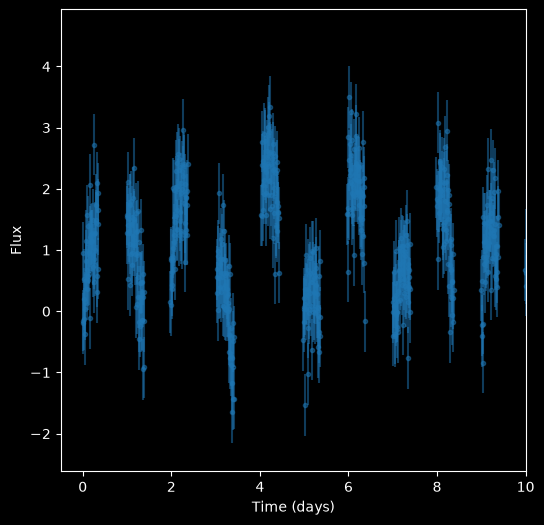

In [37]:
fig = plt.subplots(1, figsize = (6, 6), facecolor='k')
ax = plt.gca()
ax.set_facecolor('black')
ax.spines['bottom'].set_color('white')
ax.spines['top'].set_color('white')
ax.spines['left'].set_color('white')
ax.spines['right'].set_color('white')
ax.xaxis.label.set_color('white')
ax.yaxis.label.set_color('white')
ax.tick_params(axis='x', colors='white')
ax.tick_params(axis='y', colors='white')


plt.errorbar(t, y, dy, fmt=".", ms=6, alpha=0.5, rasterized=True)
plt.xlabel('Time (days)')
plt.xlim(-0.5,10)
plt.ylabel('Flux')
plt.savefig('/Users/smith/Desktop/gappy_curve', dpi=300, transparent=True)
plt.show()

### Construct periodogram using LS and compare to window function ###

Analytically, the window function power is given as 
$\begin{align} W = \sum exp(-2\pi f t)\end{align}$

The window power is then just the absolute value of W squared, $|W|^2$. You should also normalise by the length of your data (divide by len(t)^2)



In [39]:
# construct frequency grid for LS and window function

# remember:fmin is tied to baseline -> 1/T (optionally 2/T or 3/T)
# fmax is set by the Nyquist frequency (therefore temporal resolution) -> 1/2*dt
# step size is tied to width of peaks (which is tied to baseline) -> 1/nT

fmin = 
fmax = 
df = 

frequencies = np.arange(fmin, fmax, df)

LS_power = LombScarge(t, y, dy).power(frequencies)


# plot the periodogram
plt.plot()



# calculate the power of the window function at each frequency in the above grid
window_power = []


# plot the window function


SyntaxError: invalid syntax (196014541.py, line 7)